# Version learned
As previous, but Ea and A are learned only using PINN physical loss.

In [1]:
import math
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import functools

def set_seed(s):
    import random
    random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)
    np.random.seed(s)
    # torch.backends.cudnn.deterministic = True
    # torch.backends.cudnn.benchmark = False

set_seed(0)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class ScaledSigmoid(nn.Module):
    def __init__(self, min_val, max_val):
        super(ScaledSigmoid, self).__init__()
        self.min_val = min_val
        self.max_val = max_val

    def forward(self, x):
        # Apply sigmoid to squish the output to (0, 1)
        x = torch.sigmoid(x)
        # Scale and shift to the desired range [min_val, max_val]
        return self.min_val + x * (self.max_val - self.min_val)

class EquationValue(nn.Module):
    def __init__(self, input_dims, min_val, max_val):
        super().__init__()
        assert min_val < max_val, "min_val must be less than max_val"
        self.min_val = min_val
        self.max_val = max_val
        self.scaled_sigmoid = ScaledSigmoid(min_val, max_val)
        self.input_dims = input_dims
        self.linear = nn.Linear(input_dims, 1)     

        # # Target a pre-activation range of approximately [-4, 4].
        # # If we assume inputs are roughly unit variance, then scale the weights:
        # weight_range = self.max_val / math.sqrt(input_dims)  # This is a heuristic value.
        # nn.init.uniform_(self.linear.weight, -weight_range, weight_range)
        
        # # Similarly, initialize biases to cover a wide range.
        # # Here we set biases uniformly over [-4,4].
        # nn.init.uniform_(self.linear.bias, self.min_val, self.max_val)  

    def forward(self, x):
        # Apply the linear layer
        x = self.linear(x)
        # Apply the scaled sigmoid activation function
        x = self.scaled_sigmoid(x)
        return x

class DiscoveryNet(nn.Module):
    def __init__(self, input_dim, output_dim, n_units=100, epochs=1000, loss = nn.MSELoss(), lr=1e-3, loss2=None, loss2_weight=0.1, patience=0) -> None:
        super().__init__()

        self.input_dim = input_dim
        self.output_dim = output_dim
        self.epochs = epochs
        self.loss = loss
        self.loss2 = loss2
        self.loss2_weight = loss2_weight
        self.lr = lr 
        self.n_units = n_units
        self.patience = patience

        self.Ea = nn.Parameter(torch.tensor(30000, dtype=torch.float32, requires_grad=True))
        self.A = nn.Parameter(torch.tensor(1e-5, dtype=torch.float32, requires_grad=True))
    
        self.layers = nn.Sequential(
            nn.Linear(input_dim, self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
            nn.Linear(self.n_units,self.n_units),
            nn.ReLU(),
        )
        # self.out = nn.Linear(self.n_units, output_dim)

        self.d = EquationValue(self.n_units, 0, 1)
        # self.Ea = EquationValue(self.n_units, 30000, 70000)
        # self.A = EquationValue(self.n_units, 1e-5, 1e-1)  # 0.00001 to 0.1
    
    def forward(self, x):
        h = self.layers(x)

        d = self.d(h)
        # Ea = self.Ea(h)
        # A = self.A(h)
        # out = torch.cat((d, Ea, A), dim=1)

        return d

    def fit(self, X, y, scaler=None):
        Xt = np_to_tensor(X)
        yt = np_to_tensor(y)

        optimiser = optim.Adam(self.parameters(), lr=self.lr)
        self.train()
        losses = []
        data_losses = []
        physic_losses = []
        for ep in range(self.epochs):
            optimiser.zero_grad()
            outputs = self.forward(Xt)

            d = outputs[:, 0].reshape(-1, 1)
            # d = scaler.inverse_transform(d).type(torch.float32) if scaler else d

            data_loss = self.loss(yt, d)
            if self.loss2:
                physic_loss = self.loss2_weight * self.loss2(self)
                loss = data_loss + physic_loss
                physic_losses.append(physic_loss.item())
            else:
                loss = data_loss
            data_losses.append(data_loss.item())

            loss.backward()
            optimiser.step()
            losses.append(loss.item())
            if ep % int(self.epochs / 10) == 0:
                if physic_losses:
                    physic_loss_avg = np.mean(physic_losses).item()
                    # print("Estimated Ea :", outputs[:, 1].reshape(-1, 1).mean().item())
                    # print("Estimated A :", outputs[:, 2].reshape(-1, 1).mean().item())
                    estimateds = f"Ea={self.Ea.item():.2f}, A={self.A.item():.2e}"
                else:
                    physic_loss_avg = 0
                    estimateds = ""

                print(f"Epoch {ep}/{self.epochs}, loss: {np.mean(losses).item():.6f} - data_loss: {np.mean(data_losses).item():.6f} - physic_loss: {physic_loss_avg:.6f} - {estimateds}")
        return losses

    def predict(self, X):
        self.eval()
        out = self.forward(np_to_tensor(X))
        return out.detach().cpu().numpy()

def np_to_tensor(x):
    if isinstance(x, torch.Tensor) and x.device == DEVICE:
        return x
    elif isinstance(x, torch.Tensor):
        return x.to(DEVICE)
    elif isinstance(x, list):
        x = np.array(x)
    
    n_samples = len(x)
    return torch.from_numpy(x).to(torch.float).to(DEVICE).reshape(n_samples, -1)

In [2]:
# testing equationValue

etest = [EquationValue(10, 0, 1), EquationValue(10, 20000, 100000), EquationValue(10, 1e-5, 1e-1)]
x = torch.randn(10, 10)
print(x.min(), x.max())
# x = torch.randn(10, 10) ** 10
# print(x.min(), x.max())
for e in etest:
    out = e(x)
    print(out.min(), out.max())


tensor(-2.6133) tensor(3.4105)
tensor(0.2465, grad_fn=<MinBackward1>) tensor(0.5661, grad_fn=<MaxBackward1>)
tensor(56626.9102, grad_fn=<MinBackward1>) tensor(87973.2500, grad_fn=<MaxBackward1>)
tensor(0.0198, grad_fn=<MinBackward1>) tensor(0.0626, grad_fn=<MaxBackward1>)


In [3]:
class TorchMinMaxScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.min_val = torch.tensor(0, dtype=torch.float32, device=DEVICE)
        self.max_val = torch.tensor(1, dtype=torch.float32, device=DEVICE)

    def fit_transform(self, data):
        # Compute min and max values from the data
        if not isinstance(data, torch.Tensor):
            data = torch.from_numpy(data)
        self.min_val = torch.min(data, dim=0)[0].to(device=DEVICE)
        self.max_val = torch.max(data, dim=0)[0].to(device=DEVICE)
        return self.transform(data)
    
    def transform(self, x):
        prev = None
        if not isinstance(x, torch.Tensor):
            x = torch.from_numpy(x).to(device=DEVICE)
        if x.device != DEVICE:
            prev  = x.device
            x = x.to(device=DEVICE)
        # Scale x to the range [0, 1]
        scaled = (x - self.min_val) / (self.max_val - self.min_val)
        if prev != DEVICE:
            scaled = scaled.to(device=prev)
        return scaled.type(torch.float32)
    
    def inverse_transform(self, x_scaled):
        # Inverse scaling: bring x_scaled back to original range
        return x_scaled * (self.max_val - self.min_val) + self.min_val

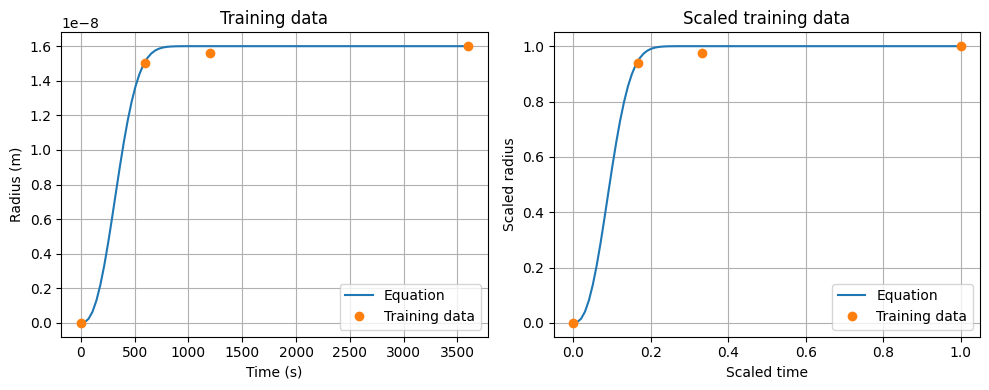

In [4]:
import numpy as np
import functools
import matplotlib.pyplot as plt

def avrami_law(t,Ea,R,T,A,n,r_max):
    K = A * np.exp(-Ea / (R * T))
    d = r_max * (1 - np.exp(-K * t**n))

    return d

np.random.seed(10)
A = 0.0015              # Increased to speed up transformation
Ea = 35000            # Lowered to increase reaction rate
T = 500               # Higher temp for faster growth
r_max = 16e-9         # Max radius in meters (30 nm)
n = 2.5
R = 8.314

TIME_MAX = 3600  # seconds

# Time array
gt_times_X = np.linspace(0, TIME_MAX, 100)
eq = functools.partial(avrami_law, Ea=Ea, A=A, T=T, r_max=r_max, n=n, R=R)
gt_d_Y = eq(gt_times_X) # * 1e9



## REAL DATA
data220 = """T,time,d\n
220,0,0\n
220,10,15\n
220,20,15.6\n
220,60,16"""
data190 = """190,0,0\n
190,10,10.5\n
190,30,12.9\n
190,60,13.9"""

data = [[0,0], [10,15], [20,15.6], [60,16]]
data = torch.tensor(data, dtype=torch.float32)
train_times_X = data[:, 0].reshape(-1, 1) * 60
train_d_Y = data[:, 1].reshape(-1, 1) * 1e-9


# Scale data
scaler_X = TorchMinMaxScaler()
scaler_Y = TorchMinMaxScaler()

# Fit and transform the training data
eq_times_X_scaled = scaler_X.fit_transform(gt_times_X.reshape(-1, 1)).type(torch.float32)
eq_d_Y_scaled = scaler_Y.fit_transform(gt_d_Y.reshape(-1, 1)).type(torch.float32)

# Transform test data using the already fitted scalers
train_times_X_scaled = scaler_X.transform(train_times_X.reshape(-1, 1)).type(torch.float32)
train_d_Y_scaled = scaler_Y.transform(train_d_Y.reshape(-1, 1)).type(torch.float32)


# Plot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
# noisy data
plt.grid()
plt.legend()
plt.title("Training data")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.subplot(1, 2, 2)
plt.plot(eq_times_X_scaled, eq_d_Y_scaled, label="Equation")
plt.plot(train_times_X_scaled.cpu().numpy(), train_d_Y_scaled.cpu().numpy() , 'o', label="Training data")
plt.grid()
plt.legend()
plt.title("Scaled training data")
plt.xlabel("Scaled time")
plt.ylabel("Scaled radius")
plt.tight_layout()
plt.show(block=False)

Epoch 0/30000, loss: 0.238346 - data_loss: 0.238346 - physic_loss: 0.000000 - 


Epoch 3000/30000, loss: 0.013981 - data_loss: 0.013981 - physic_loss: 0.000000 - 
Epoch 6000/30000, loss: 0.006995 - data_loss: 0.006995 - physic_loss: 0.000000 - 
Epoch 9000/30000, loss: 0.004664 - data_loss: 0.004664 - physic_loss: 0.000000 - 
Epoch 12000/30000, loss: 0.003498 - data_loss: 0.003498 - physic_loss: 0.000000 - 
Epoch 15000/30000, loss: 0.002798 - data_loss: 0.002798 - physic_loss: 0.000000 - 
Epoch 18000/30000, loss: 0.002332 - data_loss: 0.002332 - physic_loss: 0.000000 - 
Epoch 21000/30000, loss: 0.001999 - data_loss: 0.001999 - physic_loss: 0.000000 - 
Epoch 24000/30000, loss: 0.001749 - data_loss: 0.001749 - physic_loss: 0.000000 - 
Epoch 27000/30000, loss: 0.001555 - data_loss: 0.001555 - physic_loss: 0.000000 - 


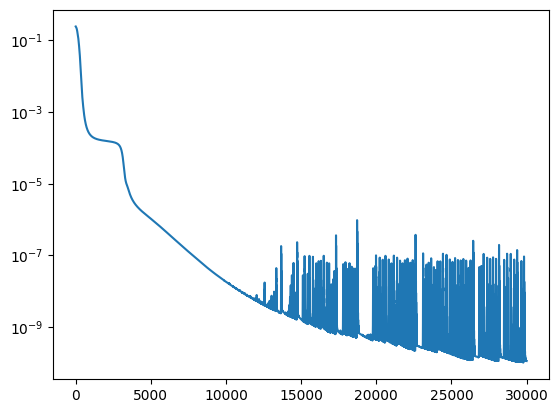

In [5]:

vanilla = DiscoveryNet(1, 3, loss2=None, loss2_weight=1, epochs=30000, lr=1e-4).to(DEVICE)
losses = vanilla.fit(train_times_X_scaled.to(DEVICE), train_d_Y_scaled.to(DEVICE), scaler_Y)
plt.plot(losses)
plt.yscale('log')

Epoch 0/10000, loss: 0.327791 - data_loss: 0.223071 - physic_loss: 0.104720 - Ea=30000.00, A=-9.00e-05
Epoch 1000/10000, loss: 0.152401 - data_loss: 0.042810 - physic_loss: 0.109591 - Ea=30000.00, A=4.50e-04
Epoch 2000/10000, loss: 0.120103 - data_loss: 0.021513 - physic_loss: 0.098590 - Ea=30000.00, A=4.36e-04
Epoch 3000/10000, loss: 0.109005 - data_loss: 0.014404 - physic_loss: 0.094601 - Ea=30000.00, A=4.24e-04
Epoch 4000/10000, loss: 0.103211 - data_loss: 0.010850 - physic_loss: 0.092361 - Ea=30000.00, A=3.86e-04
Epoch 5000/10000, loss: 0.099990 - data_loss: 0.008749 - physic_loss: 0.091241 - Ea=30000.00, A=3.93e-04
Epoch 6000/10000, loss: 0.097795 - data_loss: 0.007330 - physic_loss: 0.090465 - Ea=30000.00, A=3.81e-04
Epoch 7000/10000, loss: 0.095985 - data_loss: 0.006325 - physic_loss: 0.089660 - Ea=30000.00, A=3.65e-04
Epoch 8000/10000, loss: 0.094841 - data_loss: 0.005565 - physic_loss: 0.089276 - Ea=30000.00, A=4.31e-04
Epoch 9000/10000, loss: 0.093655 - data_loss: 0.004964 - 

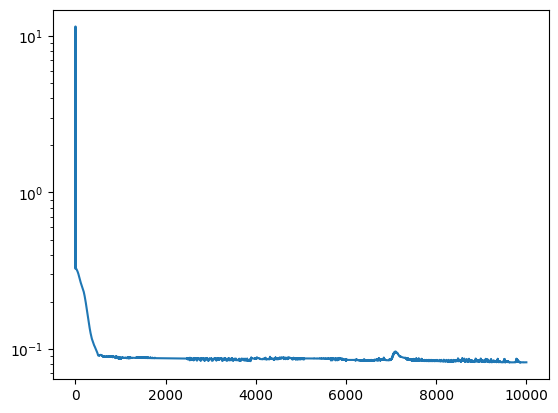

In [6]:


def set_seed(seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    

def physics_loss(model: torch.nn.Module):
    global PHYSICAL_LOSS_SCALING_FACTOR

    # Create time input for PINN
    ts = torch.linspace(0, 3600, steps=100, dtype=torch.float32).view(-1, 1).to(DEVICE).requires_grad_(True)
    ts_scaled = scaler_X.transform(ts)

    # Predict radius
    d = model(ts_scaled)
    # d = out[:, 0], out[:, 1], out[:, 2]  # [-1, 1] [0, 1]
    d = scaler_Y.inverse_transform(d)
    
    #Ea = torch.nn.functional.softplus(Ea_net) * 1e5
    #A = torch.nn.functional.softplus(A_net) * 1e-3
    # Ea = Ea_net * 1e5 
    # A = A_net * 1e-3

    Ea = model.Ea
    A = model.A

    # Compute model's derivative wrt time
    dd = torch.autograd.grad(
        d, ts, 
        grad_outputs=torch.ones_like(d), 
        create_graph=True
    )[0]

    # Compute K
    K = A * torch.exp(-Ea / (R * T))
    # Theoretical Avrami derivative
    derived_eq = r_max * K * n * ts.pow(n - 1) * torch.exp(-K * ts.pow(n))

    pde_residual = dd - derived_eq
    # pde_residual = pde_residual * 1e12

    physical_loss = torch.mean(pde_residual**2)

    if PHYSICAL_LOSS_SCALING_FACTOR is None:
        # Get the maximum residual value as a float
        val = torch.max(physical_loss).item()
        # Compute the order-of-magnitude exponent. For a value like 5.23e-6,
        # math.log10(val) ≈ -5.28, and floor(-5.28) gives -6.
        exponent = -math.floor(math.log10(val))
        # Set the scaling factor as 10 raised to the computed exponent.
        # PHYSICAL_LOSS_SCALING_FACTOR = 10 ** exponent
        PHYSICAL_LOSS_SCALING_FACTOR = 1/abs(exponent)
        # PHYSICAL_LOSS_SCALING_FACTOR = 1e10
    # pde_residual = torch.pow(pde_residual, PHYSICAL_LOSS_SCALING_FACTOR)
    physical_loss = torch.pow(physical_loss, PHYSICAL_LOSS_SCALING_FACTOR)

    return physical_loss

# PHYSICAL_LOSS_SCALING_FACTOR = 1e-12
PHYSICAL_LOSS_SCALING_FACTOR = None

set_seed(0)
scaler_X = scaler_X.to(DEVICE)
scaler_Y = scaler_Y.to(DEVICE)
curr_train_times_X = train_times_X_scaled.to(DEVICE)
curr_train_d_Y = train_d_Y_scaled.to(DEVICE)


# net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=150000, lr=1e-4).to(DEVICE)
net = DiscoveryNet(1, 3, loss2=physics_loss, loss2_weight=1, epochs=10000, lr=1e-4).to(DEVICE)
losses = net.fit(curr_train_times_X, curr_train_d_Y, scaler_Y)

plt.plot(losses)
plt.yscale('log')

Predicted A: 0.0005 std=nan, Guess A: 0.005  -  abs difference: 0.00
Predicted Ea: 30000.00 std=nan, Guess Ea: 60000  -  abs difference: 30000.00


/tmp/ipykernel_78383/3886286994.py:18: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1839.)
  print(f"Predicted A: {A.mean().item():.4f} std={A.std().item():.6f}, Guess A: {A_expected}  -  abs difference: {abs(A.mean().item() - A_expected):.2f}")
/tmp/ipykernel_78383/3886286994.py:19: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at /pytorch/aten/src/ATen/native/ReduceOps.cpp:1839.)
  print(f"Predicted Ea: {Ea.mean().item():.2f} std={Ea.std().item():.6f}, Guess Ea: {Ea_expected}  -  abs difference: {abs(Ea.mean().item() - Ea_expected):.2f}")


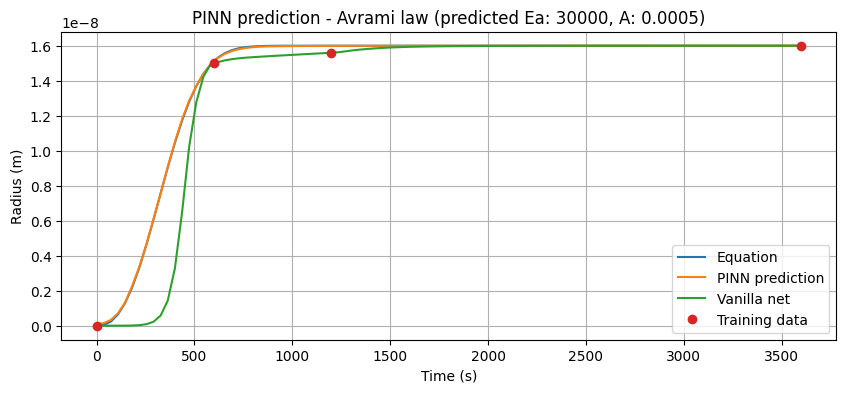

In [8]:
# plot the prediction on gt data

d = net.predict(eq_times_X_scaled)
d = torch.tensor(d, dtype=torch.float32, device=DEVICE)
# d, Ea_net, A_net = pred[:, 0], pred[:, 1], pred[:, 2]
d = scaler_Y.inverse_transform(d)
d = d.cpu().numpy()
Ea_net = net.Ea.clone().detach().cpu()
A_net = net.A.clone().detach().cpu()

# expected:
A_expected = 5e-3              # Increased to speed up transformation
Ea_expected = 60000           # Lowered to increase reaction rate

Ea = Ea_net  # torch.nn.functional.softplus(Ea_net) * 1e5
A = A_net  # torch.nn.functional.softplus(A_net) * 1e-3

print(f"Predicted A: {A.mean().item():.4f} std={A.std().item():.6f}, Guess A: {A_expected}  -  abs difference: {abs(A.mean().item() - A_expected):.2f}")
print(f"Predicted Ea: {Ea.mean().item():.2f} std={Ea.std().item():.6f}, Guess Ea: {Ea_expected}  -  abs difference: {abs(Ea.mean().item() - Ea_expected):.2f}")

vanilla_pred = vanilla.predict(eq_times_X_scaled)
vanilla_pred = torch.tensor(vanilla_pred, dtype=torch.float32, device=DEVICE)
vanilla_d = vanilla_pred[:, 0]
vanilla_d = scaler_Y.inverse_transform(vanilla_d)
vanilla_d = vanilla_d.cpu().numpy()
plt.figure(figsize=(10, 4))
# plt.subplot(1, 2, 1)
plt.plot(gt_times_X, gt_d_Y, label="Equation")
plt.plot(gt_times_X, d, label="PINN prediction")
plt.plot(gt_times_X, vanilla_d, label="Vanilla net")
# plot train data
plt.plot(train_times_X, train_d_Y , 'o', label="Training data")
plt.title(f"PINN prediction - Avrami law (predicted Ea: {Ea.mean().item():.0f}, A: {A.mean().item():.4f})")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.grid()
plt.legend()
plt.show()


# # plot all Ea and A values
# plt.figure(figsize=(10, 4))
# plt.subplot(1, 2, 1)
# plt.plot(gt_times_X, Ea, label="Ea")
# plt.legend()
# plt.grid()
# plt.subplot(1, 2, 2)
# plt.plot(gt_times_X, A, label="A")
# plt.legend()
# plt.grid()
# plt.show()


# plt.figure(figsize=(10, 4))
# # plot avrami eq using predicted A and Ea
# times = torch.linspace(200, 600, 100)
# # times = torch.linspace(350, 400, 100)
# # times = torch.linspace(0, TIME_MAX, 100)

# times_s = scaler_X.transform(times.reshape(-1, 1)).type(torch.float32).to(DEVICE)
# times_s = times_s.reshape(-1, 1)
# pred = net.predict(times_s)
# pred = torch.tensor(pred, dtype=torch.float32, device=DEVICE)
# d, Ea_net, A_net = pred[:, 0], pred[:, 1], pred[:, 2]
# d = scaler_Y.inverse_transform(d)
# d = d.cpu().numpy()
# plt.plot(times.cpu().numpy(), d, label="PINN prediction")

# eq_temp = functools.partial(avrami_law, A=A.mean().item(), Ea=Ea.mean().item(), T=T, r_max=r_max, n=n, R=R)
# eq_d_Y = eq_temp(times)
# plt.plot(times, eq_d_Y, label=f"Ea={Ea.mean().item():.2f}, A={A.mean().item():.2e} - Mean")

# eq_temp = functools.partial(avrami_law, A=A.max().item(), Ea=Ea.max().item(), T=T, r_max=r_max, n=n, R=R)
# eq_d_Y = eq_temp(times)
# plt.plot(times, eq_d_Y, label=f"Ea={Ea.max().item():.2f}, A={A.max().item():.2e} - Max")

# eq_temp = functools.partial(avrami_law, A=A.min().item(), Ea=Ea.min().item(), T=T, r_max=r_max, n=n, R=R)
# eq_d_Y = eq_temp(times)
# plt.plot(times, eq_d_Y, label=f"Ea={Ea.min().item():.2f}, A={A.min().item():.2e} - Min")

# # eq_temp = functools.partial(avrami_law, A=4e-2, Ea=47000, T=T, r_max=r_max, n=n, R=R)
# # eq_d_Y = eq_temp(times)
# # plt.plot(times, eq_d_Y, label=f"Ea=47000, A=4e-2 - Test")


# # plt.scatter(train_times_X, train_d_Y , label="Training data", color='red')

# plt.legend()
# plt.grid()
# plt.show()



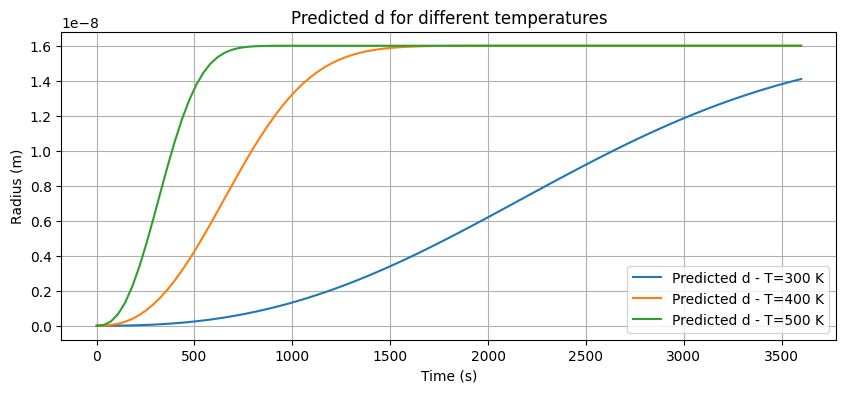

In [9]:

eq_temp = functools.partial(avrami_law, A=A.mean().item(), Ea=Ea.mean().item(), r_max=r_max, n=n, R=R)
max_time = 3600  # 1 h

times = np.linspace(0, max_time, 100)

plt.figure(figsize=(10, 4))
for temp in [300, 400, 500]:
    expeced_d = eq_temp(times, T=temp)
    plt.plot(times, expeced_d, label=f"Predicted d - T={temp} K")

plt.title("Predicted d for different temperatures")
plt.xlabel("Time (s)")
plt.ylabel("Radius (m)")
plt.legend()
plt.grid()
plt.show()


In [ ]:
# ONE WAY
# t = [0, 1, 2, ...] # seconds for a total of N steps
# d, Ea, A = nn(t)

# # at the end you have
# # d -> [N]
# # Ea -> [N] mean() std()
# # A -> [N] mean() std()
# # Ea and A uncertainty (std) -> DEPENDENT ON THE TIME

# SECOND WAY
# t = [0, 1, 2, ...] # seconds for a total of N steps
# d = nn(t)
# Ea = nn.Ea # learned 
# A = nn.A # learned 
# # d -> [N]
# # NO UNCERTAINTY IN Ea
# # INDEPENDENT FROM THE TIME
